# Philippine Vehicle Plate Number Recognition

This notebook demonstrates still-image plate reading with OpenCV candidate localization and EasyOCR text recognition. It is an educational baseline, not an official or guaranteed plate reader. Results depend on image quality, angle, lighting, plate design, and OCR model behavior.


## 1. Dependencies

Run the setup cell below once in this notebook's active kernel. It uses `%pip` so packages are installed into the same Python environment as the notebook, not a different system Python. EasyOCR downloads its recognition model the first time it is initialized; after that, recognition runs locally.

In [28]:
%pip install opencv-python matplotlib easyocr

  Using cached opencv_python_headless-5.0.0.93-cp37-abi3-win_amd64.whl.metadata (20 kB)
Using cached opencv_python_headless-5.0.0.93-cp37-abi3-win_amd64.whl (43.8 MB)
Note: you may need to restart the kernel to use updated packages.


ERROR: Could not install packages due to an OSError: [WinError 5] Access is denied: 'c:\\Users\\alexa\\AppData\\Local\\Programs\\Python\\Python313\\Lib\\site-packages\\cv2\\cv2.pyd'
Consider using the `--user` option or check the permissions.


[notice] A new release of pip is available: 24.3.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [29]:
from pathlib import Path
import re

import cv2
import matplotlib.pyplot as plt
import numpy as np

## 2. Load a plate image

Use a clear, well-lit image with the full vehicle plate visible. Keep images you process private and ensure you have permission to use them. The image is read from disk and is not uploaded by this notebook.

Image size: 736 x 285 pixels


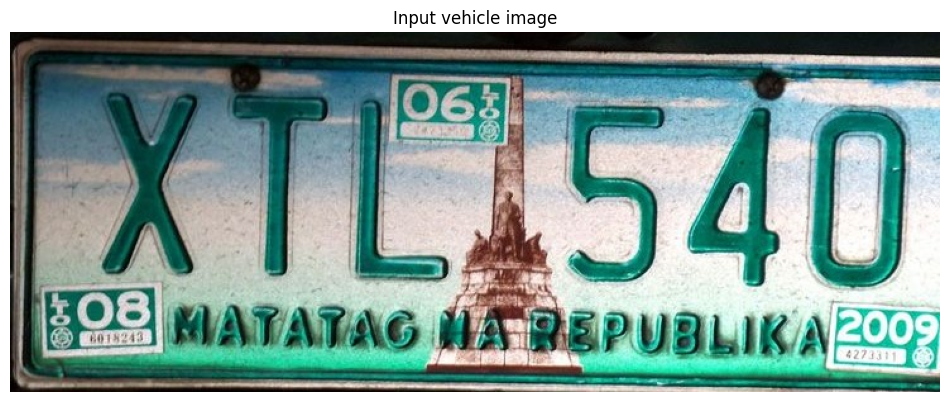

In [30]:
IMAGE_PATH = Path('Assets/plate.jpg')

image_bgr = cv2.imread(str(IMAGE_PATH))
if image_bgr is None:
    raise FileNotFoundError(
        f'Could not load {IMAGE_PATH}. Add a vehicle image at this path or update IMAGE_PATH.'
    )

image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
image_height, image_width = image_rgb.shape[:2]
print(f'Image size: {image_width} x {image_height} pixels')

plt.figure(figsize=(12, 7))
plt.imshow(image_rgb)
plt.title('Input vehicle image')
plt.axis('off')
plt.show()

## 3. Prepare image views

Bilateral filtering reduces some image noise while preserving edges. Canny highlights edges that may form the plate border and printed characters.

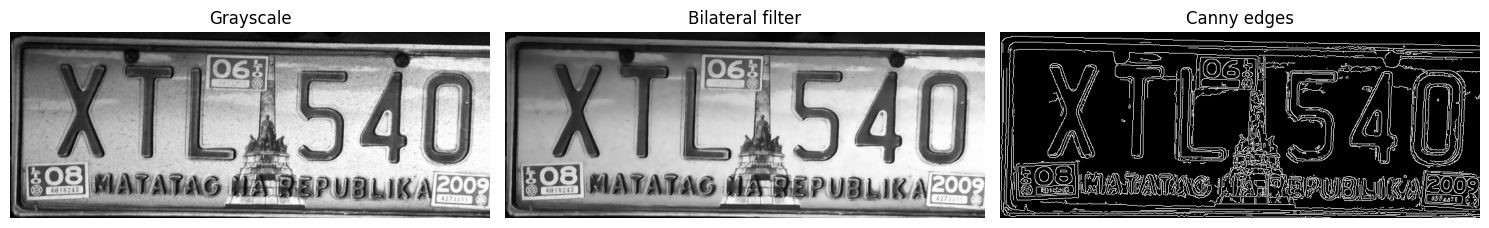

In [31]:
gray = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2GRAY)
filtered_gray = cv2.bilateralFilter(gray, 11, 17, 17)
edges = cv2.Canny(filtered_gray, 40, 150)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for axis, view, title in zip(
    axes,
    (gray, filtered_gray, edges),
    ('Grayscale', 'Bilateral filter', 'Canny edges'),
):
    axis.imshow(view, cmap='gray')
    axis.set_title(title)
    axis.axis('off')
plt.tight_layout()
plt.show()

## 4. Find plate-shaped candidate regions

Close nearby edges, then filter contours by size and a broad plate-like aspect ratio. If the input itself is a tightly cropped plate image, keep its near-full-frame contour instead of rejecting it as too large. The original image is also retained for OCR as a fallback.

Plate-shaped candidates: 1


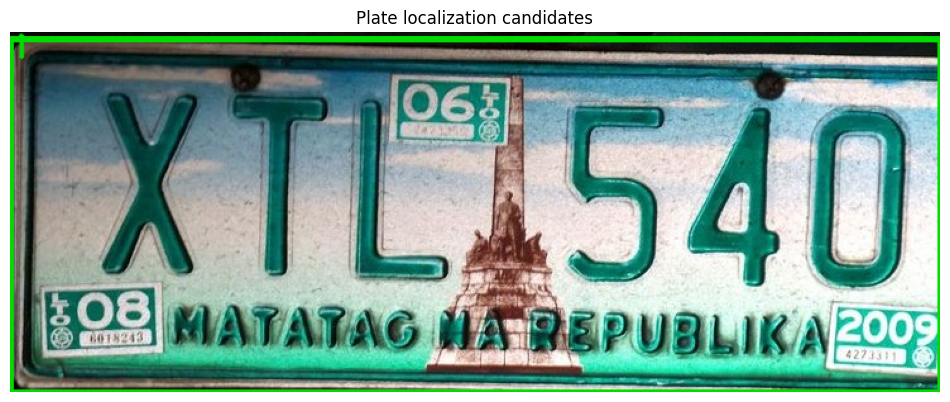

In [32]:
close_width = max(15, image_width // 120)
close_height = max(3, image_height // 300)
close_kernel = cv2.getStructuringElement(
    cv2.MORPH_RECT, (close_width, close_height)
)
closed_edges = cv2.morphologyEx(edges, cv2.MORPH_CLOSE, close_kernel)
contours, _ = cv2.findContours(
    closed_edges, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
)

minimum_area = image_width * image_height * 0.0005
maximum_area = image_width * image_height * 0.25
candidate_boxes = []
for contour in contours:
    x, y, box_width, box_height = cv2.boundingRect(contour)
    area = box_width * box_height
    aspect_ratio = box_width / max(box_height, 1)
    tightly_cropped_plate = (
        x <= image_width * 0.02
        and y <= image_height * 0.05
        and x + box_width >= image_width * 0.98
        and y + box_height >= image_height * 0.95
    )
    if (
        area >= minimum_area
        and (area <= maximum_area or tightly_cropped_plate)
        and box_width >= image_width * 0.06
        and 2.0 <= aspect_ratio <= 6.5
    ):
        candidate_boxes.append((x, y, box_width, box_height, area))

# Prefer larger regions and remove heavily overlapping duplicate rectangles.
candidate_boxes.sort(key=lambda box: box[4], reverse=True)
plate_candidates = []
for candidate in candidate_boxes:
    x, y, box_width, box_height, _ = candidate
    overlaps_existing = False
    for kept_x, kept_y, kept_width, kept_height, _ in plate_candidates:
        intersection_width = max(0, min(x + box_width, kept_x + kept_width) - max(x, kept_x))
        intersection_height = max(0, min(y + box_height, kept_y + kept_height) - max(y, kept_y))
        intersection = intersection_width * intersection_height
        smaller_area = min(box_width * box_height, kept_width * kept_height)
        if smaller_area and intersection / smaller_area > 0.6:
            overlaps_existing = True
            break
    if not overlaps_existing:
        plate_candidates.append(candidate)

plate_candidates = plate_candidates[:10]
print(f'Plate-shaped candidates: {len(plate_candidates)}')

candidate_view = image_rgb.copy()
for candidate_number, (x, y, box_width, box_height, _) in enumerate(plate_candidates, start=1):
    cv2.rectangle(candidate_view, (x, y), (x + box_width, y + box_height), (0, 220, 0), 3)
    cv2.putText(
        candidate_view, str(candidate_number), (x, max(y - 8, 20)),
        cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 220, 0), 2, cv2.LINE_AA,
    )

plt.figure(figsize=(12, 7))
plt.imshow(candidate_view)
plt.title('Plate localization candidates')
plt.axis('off')
plt.show()

## 5. Read candidate text with EasyOCR

EasyOCR detects and recognizes text in both the full image and candidate crops. Running on the full image provides a fallback if contour-based localization misses the plate. Text cleanup removes spaces and punctuation; the broad format check is only a ranking hint, not proof that a result is a valid Philippine registration.

In [33]:
try:
    import easyocr
except ImportError as error:
    raise ImportError(
        'EasyOCR is required for text recognition. Install it with '
            'run the Dependencies setup cell above, then rerun this cell.'
    ) from error

import torch
torch.set_num_threads(1)
reader = easyocr.Reader(['en'], gpu=False)
ocr_inputs = [('full image', image_rgb, (0, 0))]
for candidate_number, (x, y, box_width, box_height, _) in enumerate(plate_candidates, start=1):
    padding_x = int(box_width * 0.04)
    padding_y = int(box_height * 0.12)
    left = max(0, x - padding_x)
    top = max(0, y - padding_y)
    right = min(image_width, x + box_width + padding_x)
    bottom = min(image_height, y + box_height + padding_y)
    crop = image_rgb[top:bottom, left:right]
    if crop.size:
        ocr_inputs.append((f'candidate {candidate_number}', crop, (left, top)))

def clean_plate_text(text):
    return re.sub(r'[^A-Z0-9]', '', text.upper())

def plate_format_bonus(text):
    # A broad alphanumeric shape bonus; plate formats vary by series and type.
    if re.fullmatch(r'[A-Z]{2,3}\d{3,4}', text):
        return 0.15
    if 5 <= len(text) <= 8 and re.search(r'[A-Z]', text) and re.search(r'\d', text):
        return 0.05
    return 0.0

ocr_results = []
for source_name, source_image, (offset_x, offset_y) in ocr_inputs:
    for polygon, text, confidence in reader.readtext(source_image, detail=1, paragraph=False):
        cleaned_text = clean_plate_text(text)
        if not cleaned_text:
            continue
        polygon = np.asarray(polygon, dtype=np.float32)
        polygon[:, 0] += offset_x
        polygon[:, 1] += offset_y
        score = float(confidence) + plate_format_bonus(cleaned_text)
        ocr_results.append({
            'text': cleaned_text,
            'raw_text': text,
            'confidence': float(confidence),
            'score': score,
            'source': source_name,
            'polygon': polygon,
        })

if not ocr_results:
    raise ValueError(
        'OCR did not return any readable text. Try a sharper, closer, front-facing image.'
    )

ocr_results.sort(key=lambda result: result['score'], reverse=True)
for result in ocr_results[:10]:
    print(
        f"{result['text']} | confidence={result['confidence']:.3f} "
        f"| source={result['source']}"
    )

Using CPU. Note: This module is much faster with a GPU.


XTLI4O | confidence=0.659 | source=full image
XTLI4O | confidence=0.659 | source=candidate 1
593 | confidence=0.219 | source=full image
593 | confidence=0.219 | source=candidate 1
BOG3 | confidence=0.175 | source=full image
BOG3 | confidence=0.175 | source=candidate 1
4UD | confidence=0.056 | source=full image
4UD | confidence=0.056 | source=candidate 1
MATATAGUTREPUBLIK | confidence=0.027 | source=full image
MATATAGUTREPUBLIK | confidence=0.027 | source=candidate 1


## 6. Show the highest-ranked reading

Review the image and OCR confidence manually before relying on any reading. Low-confidence or visually inconsistent results should not be treated as a valid plate number.

Best OCR reading: XTLI4O
OCR confidence: 0.659
Read from: full image


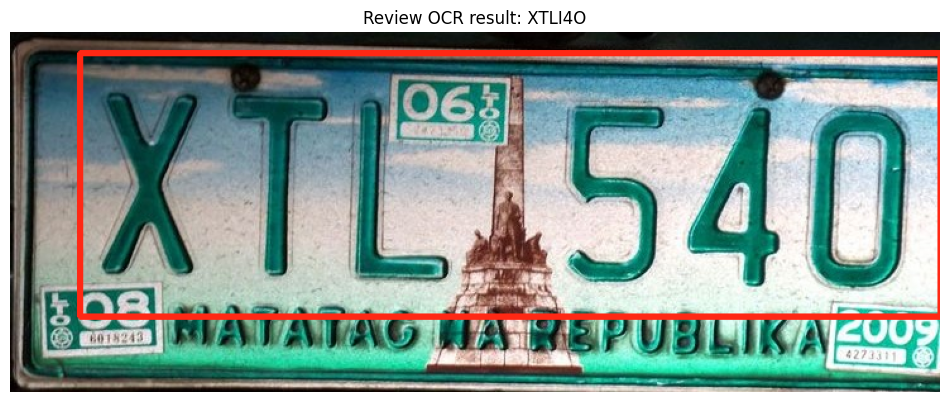

In [34]:
best_result = ocr_results[0]
review_image = image_rgb.copy()
polygon = np.round(best_result['polygon']).astype(np.int32)
cv2.polylines(review_image, [polygon], True, (255, 40, 20), 3)

print(f"Best OCR reading: {best_result['text']}")
print(f"OCR confidence: {best_result['confidence']:.3f}")
print(f"Read from: {best_result['source']}")

plt.figure(figsize=(12, 7))
plt.imshow(review_image)
plt.title(f"Review OCR result: {best_result['text']}")
plt.axis('off')
plt.show()